In [4]:

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io
import re

print("Selecciona los dos archivos Excel de las estaciones")

archivos = files.upload()

print("\nArchivos cargados:")
for nombre in archivos:
    print(nombre)


Selecciona los dos archivos Excel de las estaciones


Saving Estacion_2_.xlsx to Estacion_2_ (1).xlsx
Saving Estación_1.xlsx to Estación_1 (1).xlsx

Archivos cargados:
Estacion_2_ (1).xlsx
Estación_1 (1).xlsx


In [5]:
nombres = list(archivos.keys())
if len(nombres) != 2:
    raise ValueError("Debes cargar exactamente dos archivos Excel.")
def leer_estacion(nombre, contenido):
    temporal = pd.read_excel(
        io.BytesIO(contenido),
        header=None)

    fila_encabezado = None
    for i in range(min(5, len(temporal))):
        valores = temporal.iloc[i].astype(str).tolist()

        if "Local Date Time" in valores:
            fila_encabezado = i
            break

    if fila_encabezado is None:
        raise ValueError(
            f"No se encontró la columna Local Date Time en {nombre}")

    df = pd.read_excel(
        io.BytesIO(contenido),
        header=fila_encabezado )
    df.columns = df.columns.astype(str).str.strip()

    return df
df1 = leer_estacion(nombres[0], archivos[nombres[0]])
df2 = leer_estacion(nombres[1], archivos[nombres[1]])

print("Estación 1:", nombres[0])
print("Estación 2:", nombres[1])

print("\nColumnas de la estación 1:")
print(df1.columns.tolist())

print("\nColumnas de la estación 2:")
print(df2.columns.tolist())


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Estación 1: Estacion_2_ (1).xlsx
Estación 2: Estación_1 (1).xlsx

Columnas de la estación 1:
['Local Date Time', 'Device Id', 'Temperature Indoor', 'Temperature Indoor Dew Point', 'Temperature Outdoor', 'Temperature Outdoor At', 'Temperature Outdoor Dew Point', 'Temperature Outdoor Feels Like', 'Humidity Indoor', 'Humidity Outdoor', 'Wind Gust', 'Wind Average', 'Wind Direct', 'Wind Direct Sec', 'Rainfall Rate', 'Rainfall 24h', 'Rainfall Week', 'Rainfall Month', 'Rainfall Total', 'Pressure Absolute', 'Pressure Relative']

Columnas de la estación 2:
['Local Date Time', 'Device Id', 'Temperature Indoor', 'Temperature Indoor Dew Point', 'Temperature Outdoor', 'Temperature Outdoor At', 'Temperature Outdoor Dew Point', 'Temperature Outdoor Feels Like', 'Humidity Indoor', 'Humidity Outdoor', 'Wind Gust', 'Wind Average', 'Wind Direct', 'Wind Direct Sec', 'Rainfall Rate', 'Rainfall 24h', 'Rainfall Week', 'Rainfall Month', 'Rainfall Total', 'Pressure Absolute', 'Pressure Relative']


In [10]:

import pandas as pd
import numpy as np
fecha = "Local Date Time"

variables = { "Temperature Outdoor": "Temperatura exterior (°C)",
    "Humidity Outdoor": "Humedad relativa (%)",
    "Pressure Absolute": "Presión atmosférica (hPa)",
    "Wind Average": "Velocidad del viento (km/h)"}

def limpiar_datos(df, nombre):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()
    columnas_necesarias = [fecha] + list(variables.keys())
    faltantes = [
        columna for columna in columnas_necesarias
        if columna not in df.columns ]

    if faltantes:
        raise ValueError(
            f"Faltan columnas en {nombre}: {faltantes}")

    df[fecha] = pd.to_datetime(
        df[fecha],
        errors="coerce")

    for columna in variables.keys():

        df[columna] = pd.to_numeric(
            df[columna]
            .astype(str)
            .str.replace(",", ".", regex=False)
            .str.replace(
                r"[^0-9.-]",
                "",
                regex=True),
            errors="coerce")

    df = df.dropna(subset=[fecha])
    df = df.sort_values(fecha)
    print("\n================================")
    print(nombre)
    print("================================")

    print("Total de registros:", len(df))
    print("Fecha inicial:", df[fecha].min())
    print("Fecha final:", df[fecha].max())
    print("\nValores vacíos por variable:")
    print(df[list(variables.keys())].isnull().sum())
    print("\nEstadísticas descriptivas:")
    display(
        df[list(variables.keys())].describe().round(2))
    return df

df1 = limpiar_datos(
    df1,
    "ESTACIÓN METEOROLÓGICA 1")
df2 = limpiar_datos(
    df2,
    "ESTACIÓN METEOROLÓGICA 2")

print("\n================================")
print("LIMPIEZA FINALIZADA")
print("================================")

print("Estación 1:", df1.shape)
print("Estación 2:", df2.shape)
print("\nVariables para la comparación:")
for columna, nombre in variables.items():
    print("-", nombre, ":", columna)
print("\nPrimeros registros de la estación 1:")
display(df1.head())

print("\nPrimeros registros de la estación 2:")
display(df2.head())




ESTACIÓN METEOROLÓGICA 1
Total de registros: 4659
Fecha inicial: 2026-10-10 00:05:00
Fecha final: 2026-10-27 00:00:00

Valores vacíos por variable:
Temperature Outdoor    0
Humidity Outdoor       0
Pressure Absolute      0
Wind Average           0
dtype: int64

Estadísticas descriptivas:


,Temperature Outdoor,Humidity Outdoor,Pressure Absolute,Wind Average
count,4659.00,4659.00,4659.00,4659.00
mean,11.79,82.72,20.70,4.32
std,3.99,14.59,0.03,5.35
min,2.90,42.00,20.60,0.00
25%,8.90,71.00,20.67,0.00
50%,10.90,88.00,20.70,0.00
75%,14.90,96.00,20.72,7.99
max,21.30,99.00,20.77,24.37



ESTACIÓN METEOROLÓGICA 2
Total de registros: 4896
Fecha inicial: 2026-10-03 00:05:00
Fecha final: 2026-10-20 00:00:00

Valores vacíos por variable:
Temperature Outdoor    219
Humidity Outdoor       219
Pressure Absolute      202
Wind Average           219
dtype: int64

Estadísticas descriptivas:


,Temperature Outdoor,Humidity Outdoor,Pressure Absolute,Wind Average
count,4677.00,4677.00,4694.00,4677.00
mean,12.49,78.63,20.74,4.34
std,4.64,16.81,0.03,5.15
min,4.50,28.00,20.64,0.00
25%,8.80,68.00,20.72,0.00
50%,11.70,85.00,20.74,2.95
75%,15.40,92.00,20.76,6.98
max,29.10,99.00,20.82,25.88



LIMPIEZA FINALIZADA
Estación 1: (4659, 21)
Estación 2: (4896, 21)

Variables para la comparación:
- Temperatura exterior (°C) : Temperature Outdoor
- Humedad relativa (%) : Humidity Outdoor
- Presión atmosférica (hPa) : Pressure Absolute
- Velocidad del viento (km/h) : Wind Average

Primeros registros de la estación 1:


,Local Date Time,Device Id,Temperature Indoor,Temperature Indoor Dew Point,Temperature Outdoor,Temperature Outdoor At,Temperature Outdoor Dew Point,Temperature Outdoor Feels Like,Humidity Indoor,Humidity Outdoor,...,Wind Average,Wind Direct,Wind Direct Sec,Rainfall Rate,Rainfall 24h,Rainfall Week,Rainfall Month,Rainfall Total,Pressure Absolute,Pressure Relative
0,2026-10-10 00:05:00,1020BA5F5B38,14.32 ℃,8.72 ℃,8.2,7.6 ℃,7.45 ℃,8.2 ℃,69 %,95,...,0.0,165,SSE,0.0,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,20.74,29.93 inHg
1,2026-10-10 00:10:00,1020BA5F5B38,14.32 ℃,8.72 ℃,8.1,7.48 ℃,7.35 ℃,8.1 ℃,69 %,95,...,0.0,165,SSE,0.0,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,20.73,29.93 inHg
2,2026-10-10 00:15:00,1020BA5F5B38,14.31 ℃,8.72 ℃,8.1,7.48 ℃,7.35 ℃,8.1 ℃,69 %,95,...,0.0,165,SSE,0.0,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,20.73,29.94 inHg
3,2026-10-10 00:20:00,1020BA5F5B38,14.29 ℃,8.69 ℃,8.0,7.36 ℃,7.31 ℃,8.0 ℃,69 %,96,...,0.0,165,SSE,0.0,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,20.72,29.93 inHg
4,2026-10-10 00:25:00,1020BA5F5B38,14.27 ℃,8.67 ℃,7.8,7.11 ℃,7.06 ℃,7.8 ℃,69 %,95,...,0.0,165,SSE,0.0,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,1.29 mm/hr,20.72,29.93 inHg



Primeros registros de la estación 2:


,Local Date Time,Device Id,Temperature Indoor,Temperature Indoor Dew Point,Temperature Outdoor,Temperature Outdoor At,Temperature Outdoor Dew Point,Temperature Outdoor Feels Like,Humidity Indoor,Humidity Outdoor,...,Wind Average,Wind Direct,Wind Direct Sec,Rainfall Rate,Rainfall 24h,Rainfall Week,Rainfall Month,Rainfall Total,Pressure Absolute,Pressure Relative
0,2026-10-03 00:05:00,1020BA5F4EA4,13.53 ℃,9.0 ℃,9.5,9.02 ℃,7.95 ℃,9.5 ℃,74 %,90.0,...,0.0,347.0,NNW,0.0,69.93 mm/hr,69.93 mm/hr,80.65 mm/hr,80.65 mm/hr,20.77,29.92 inHg
1,2026-10-03 00:10:00,1020BA5F4EA4,13.53 ℃,9.0 ℃,9.5,9.06 ℃,8.11 ℃,9.5 ℃,74 %,91.0,...,0.0,347.0,NNW,0.0,69.93 mm/hr,69.93 mm/hr,80.65 mm/hr,80.65 mm/hr,20.77,29.94 inHg
2,2026-10-03 00:15:00,1020BA5F4EA4,13.51 ℃,8.98 ℃,9.5,9.06 ℃,8.11 ℃,9.5 ℃,74 %,91.0,...,0.0,347.0,NNW,0.0,69.93 mm/hr,69.93 mm/hr,80.65 mm/hr,80.65 mm/hr,20.77,29.93 inHg
3,2026-10-03 00:20:00,1020BA5F4EA4,13.5 ℃,8.97 ℃,9.5,9.06 ℃,8.11 ℃,9.5 ℃,74 %,91.0,...,0.0,347.0,NNW,0.0,69.93 mm/hr,69.93 mm/hr,80.65 mm/hr,80.65 mm/hr,20.77,29.94 inHg
4,2026-10-03 00:25:00,1020BA5F4EA4,13.49 ℃,8.96 ℃,9.5,9.06 ℃,8.11 ℃,9.5 ℃,74 %,91.0,...,0.0,324.0,NW,0.0,69.93 mm/hr,69.93 mm/hr,80.65 mm/hr,80.65 mm/hr,20.77,29.94 inHg


In [11]:
fecha_inicio = pd.Timestamp("2026-10-10 00:00:00")
fecha_fin = pd.Timestamp("2026-10-17 00:00:00")

semana1 = df1[(df1[fecha] >= fecha_inicio) &
    (df1[fecha] < fecha_fin)].copy()

semana2 = df2[(df2[fecha] >= fecha_inicio) &
    (df2[fecha] < fecha_fin)].copy()

print("===================================")
print("COMPARACIÓN MICROCLIMÁTICA")
print("===================================")
print("Periodo: 10 al 16 de octubre de 2026")
print("Registros estación 1:", len(semana1))
print("Registros estación 2:", len(semana2))

if semana1.empty or semana2.empty:
    raise ValueError("No hay registros en el periodo seleccionado.")


COMPARACIÓN MICROCLIMÁTICA
Periodo: 10 al 16 de octubre de 2026
Registros estación 1: 1820
Registros estación 2: 2016


In [12]:

def calcular_promedio_horario(df):

    return (
        df.set_index(fecha)[list(variables.keys())]
        .resample("1h")
        .mean()
    )

horario1 = calcular_promedio_horario(semana1)
horario2 = calcular_promedio_horario(semana2)

# Conservar únicamente las horas que tienen datos
# en las dos estaciones para cada variable
comparacion = horario1.join(
    horario2,
    how="inner",
    lsuffix="_E1",
    rsuffix="_E2"
)

print("Horas comunes:", len(comparacion))
display(comparacion.head())


Horas comunes: 168


,Temperature Outdoor_E1,Humidity Outdoor_E1,Pressure Absolute_E1,Wind Average_E1,Temperature Outdoor_E2,Humidity Outdoor_E2,Pressure Absolute_E2,Wind Average_E2
Local Date Time,,,,,,,,
2026-10-10 00:00:00,7.781818,95.909091,20.717273,0.0,8.716667,95.083333,20.762500,0.000000
2026-10-10 01:00:00,8.141667,96.333333,20.696667,0.0,8.916667,93.750000,20.741667,3.468333
2026-10-10 02:00:00,7.716667,96.500000,20.685833,0.0,8.508333,94.333333,20.728333,1.666667
2026-10-10 03:00:00,8.216667,96.083333,20.677500,0.0,8.925000,93.250000,20.725833,0.000000
2026-10-10 04:00:00,7.983333,96.083333,20.685000,0.0,8.700000,94.000000,20.729167,0.000000


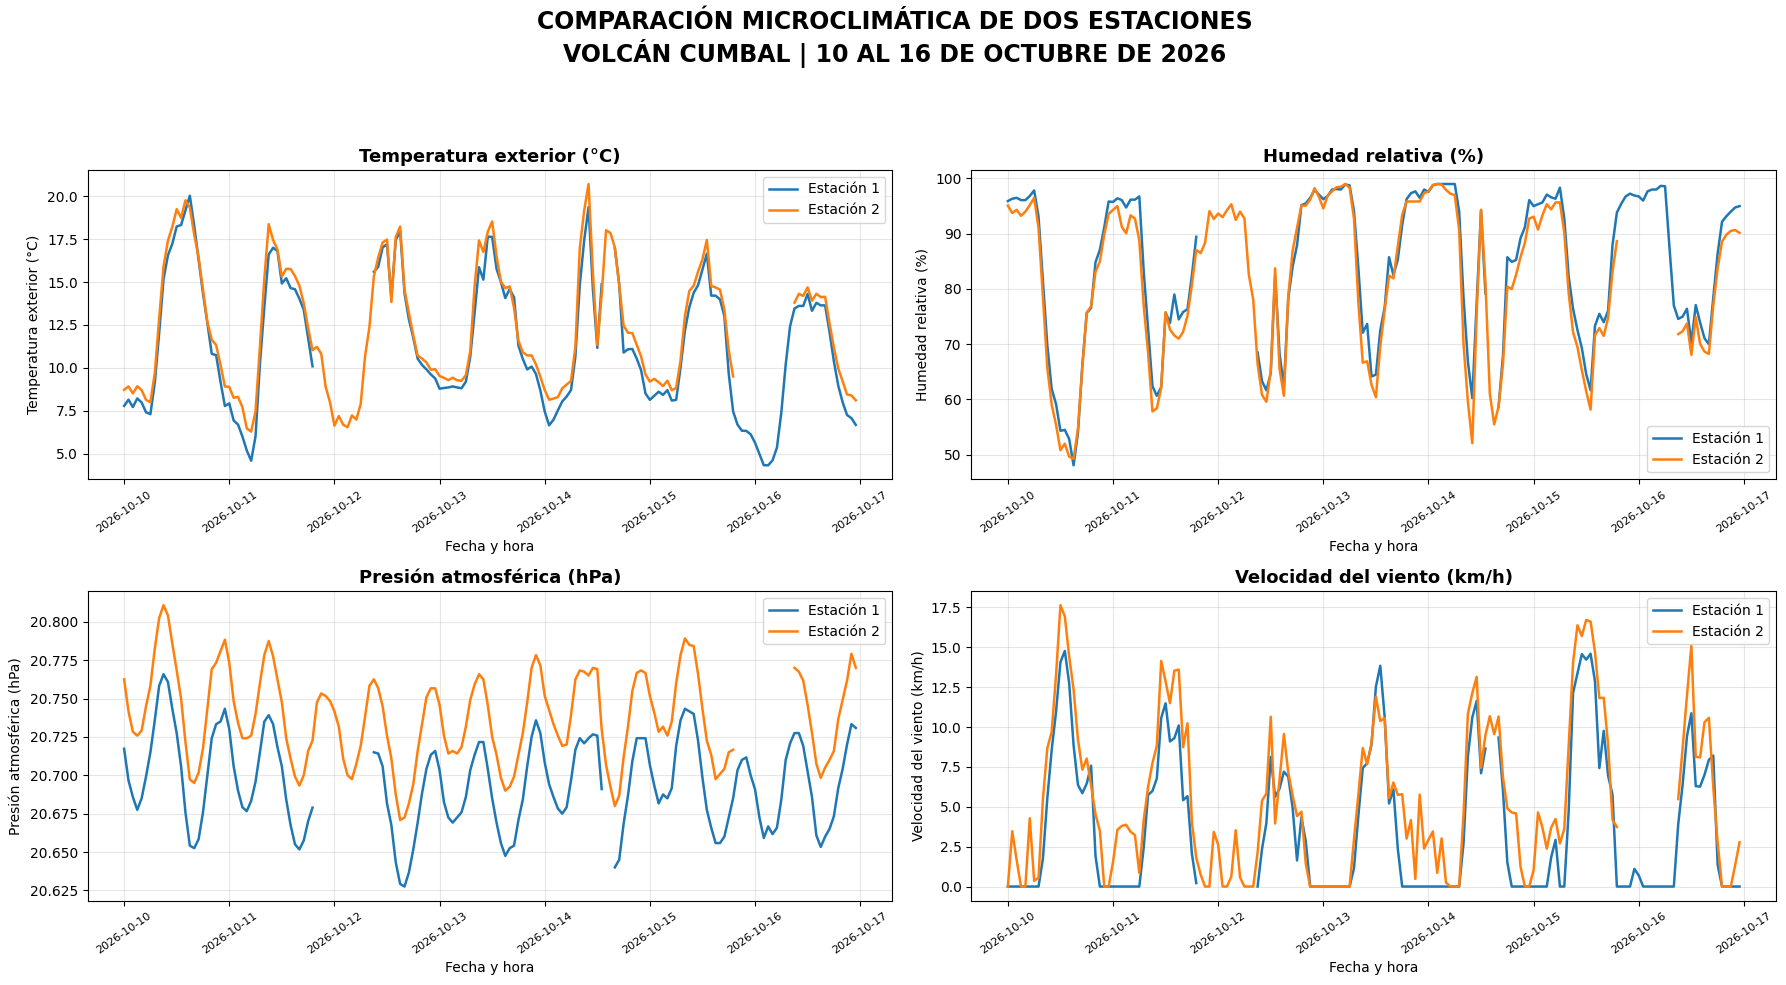

In [14]:

import matplotlib.pyplot as plt
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(18, 10))

fig.suptitle(
    "COMPARACIÓN MICROCLIMÁTICA DE DOS ESTACIONES\n"
    "VOLCÁN CUMBAL | 10 AL 16 DE OCTUBRE DE 2026",
    fontsize=17,
    fontweight="bold")
for ax, (variable, titulo) in zip(
    axes.flatten(),
    variables.items()):

    ax.plot(
        comparacion.index,
        comparacion[variable + "_E1"],
        label="Estación 1",
        linewidth=1.8 )

    ax.plot(
        comparacion.index,
        comparacion[variable + "_E2"],
        label="Estación 2",
        linewidth=1.8)

    ax.set_title(titulo,
        fontsize=13,
        fontweight="bold")

    ax.set_xlabel("Fecha y hora", fontsize=10)
    ax.set_ylabel(titulo, fontsize=10)
    ax.legend(loc="best", fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.tick_params(
        axis="x",
        rotation=35,
        labelsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(
    "Comparacion_Microclimatica_4_Graficas.png",
    dpi=300,
    bbox_inches="tight")
plt.show()
